C:\Users\MADHU\AppData\Local\Temp\ipykernel_19548\3545298683.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='viridis')


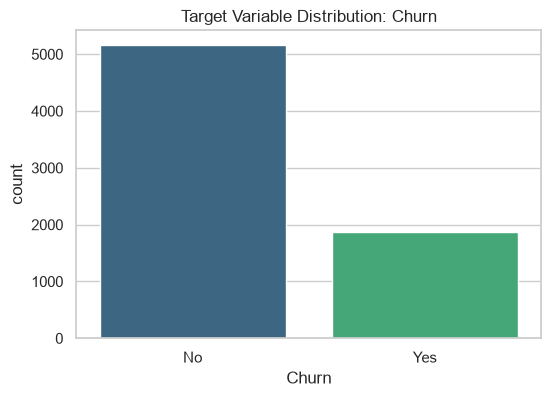

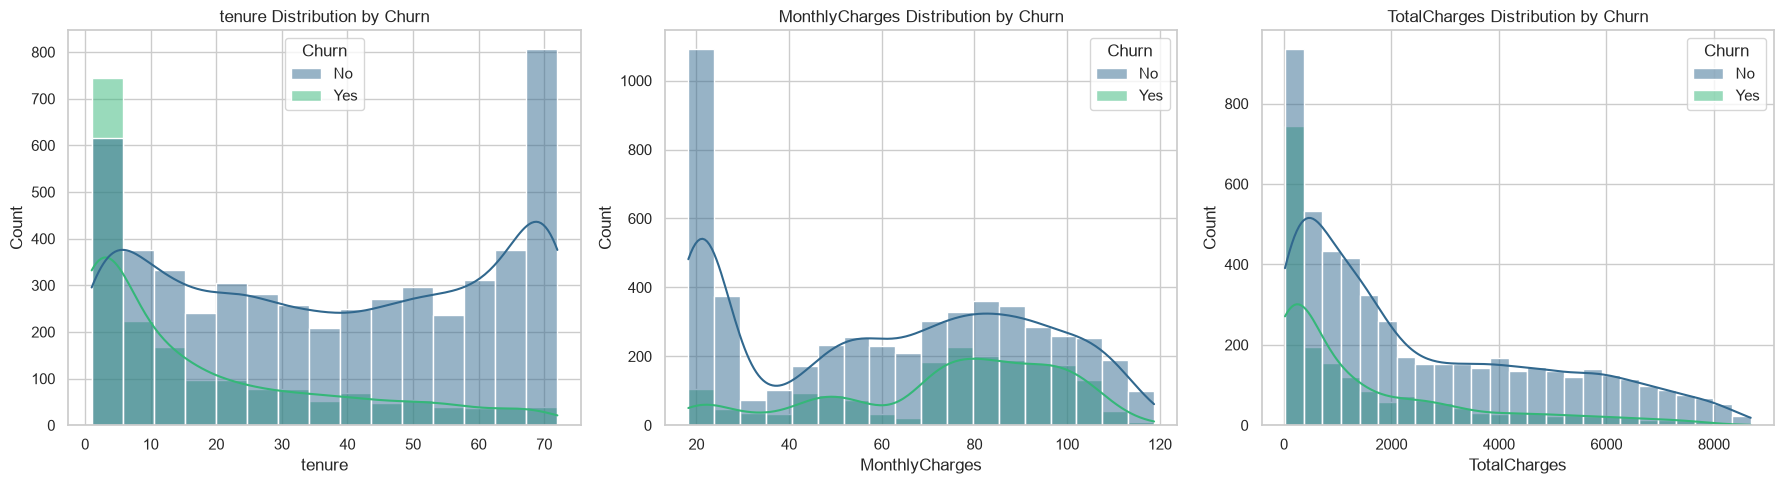

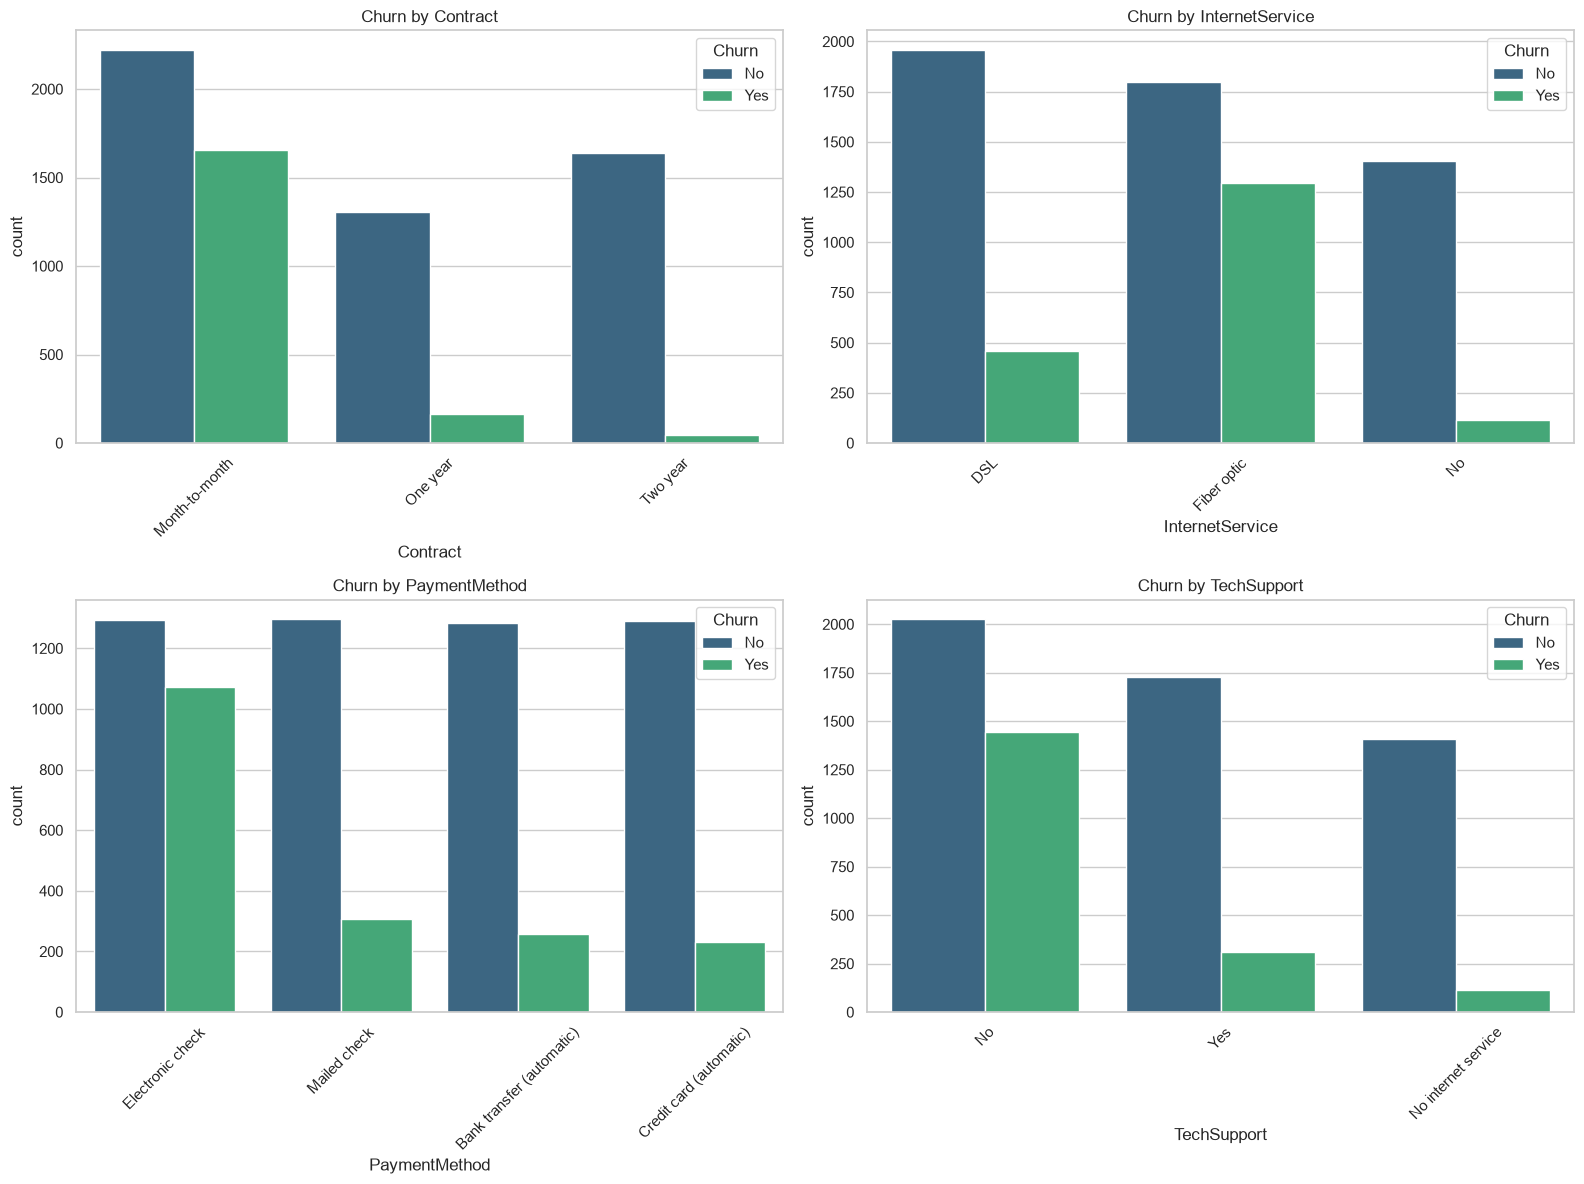

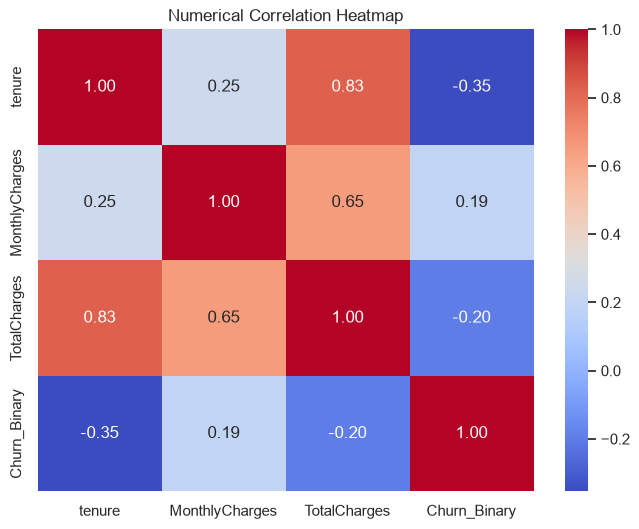

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Load Data
# Assuming the file is downloaded as 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# 2. Data Preprocessing & Quality Fixes
# Drop customerID
df.drop('customerID', axis=1, inplace=True)

# Fix TotalCharges data type and handle hidden missing values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(" ", np.nan))
df.dropna(subset=['TotalCharges'], inplace=True) # Dropping the 11 rows

# Cast SeniorCitizen to object (categorical) for analysis
df['SeniorCitizen'] = df['SeniorCitizen'].astype(str)

# 3. Exploratory Data Analysis (EDA)
sns.set_theme(style="whitegrid")

# Target Variable Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette='viridis')
plt.title('Target Variable Distribution: Churn')
plt.show()

# Numerical Features vs. Churn
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue='Churn', kde=True, ax=axes[i], palette='viridis')
    axes[i].set_title(f'{col} Distribution by Churn')
plt.tight_layout()
plt.show()

# Key Categorical Features vs. Churn
categorical_cols = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for i, col in enumerate(categorical_cols):
    ax = axes[i//2, i%2]
    sns.countplot(data=df, x=col, hue='Churn', ax=ax, palette='viridis')
    ax.set_title(f'Churn by {col}')
    ax.tick_params(axis='x', rotation=45)
    
plt.tight_layout()
plt.show()

# Correlation Heatmap for Numerical Features
plt.figure(figsize=(8, 6))
# Convert Churn to binary for correlation
df['Churn_Binary'] = df['Churn'].map({'Yes': 1, 'No': 0})
corr_matrix = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_Binary']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Numerical Correlation Heatmap')
plt.show()